# Practical 1 - Part I: Can we reconstruct a temperature field without temperature measurements?

**Machine Learning for Physics 2026 - MSIAM / Ensimag**

*Author: Filippo Masi*

Problem: Imagine a heated bar whose governing equation and endpoint temperatures are known, but whose temperature inside the bar has not been measured. Can a neural network predict a physically meaningful field without any interior training labels?

In this practical, you will build a physics-informed neural network (PINN) from almost nothing: a differentiable artificial neural network ansatz function (MLP), a PDE residual, boundary information and an optimizer. The objective is to test which conditions the network actually learned and which conditions can be guaranteed by its structure.

At the end, you should be able to
- Compute first and second input derivatives through an multi-layer perceptron (MLP) using automatic differentiation.
- Train a neural network from the PDE and boundary conditions.
- Distinguish the training residual, the validation error and the boundary mismatch.
- Explain and demonstrate why soft and hard constraints are not interchangeable.

Suggestion: First run a small number of optimizer steps to debug.

Working principle: Predict what a code cell should show, complete the `TODO`s, run the assertion test, and then explain what you observed. 

## 1. Start from the physics: what information is available?

A bar occupies $0<x<1$. Its steady temperature $u(x)$ satisfies

$$-u_{xx}(x)=f(x), \qquad u(0)=u(1)=0.$$

The source $f$ describes heating along the bar while the boundary conditions fix its temperature at the two ends. To judge whether our PINN works, we choose a reference solution:

$$u_{\mathrm{exact}}(x)=\sin(\pi x),\qquad f(x)=\pi^2\sin(\pi x).$$

We are allowed to know $f$ and the two boundary temperatures during training. We will not give the network values of $u_{\mathrm{exact}}$ inside the domain. We keep that analytical solution for validation only. This is precisely what makes the problem a meaningful PINN test rather than supervised curve fitting.

- Before running the setup: Differentiate $u_{\mathrm{exact}}$ twice to verify the source.
- What information would be missing if we provided the equation but neither boundary condition?

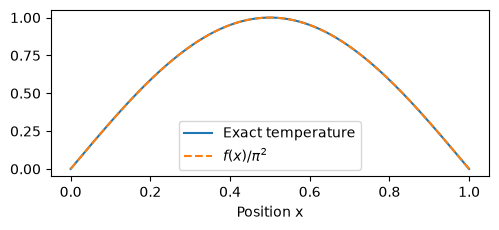

In [4]:
import time
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

# Keep the practical reproducible and reasonably quick on classroom CPUs.
torch.set_num_threads(1)
torch.set_default_dtype(torch.float32)
torch.manual_seed(13)
np.random.seed(13)
device = torch.device('cpu')
PI = np.pi


def u_exact(x):
    """Manufactured exact solution. Use for error plots, never as PINN labels."""
    return torch.sin(PI * x)


def source(x):
    """Volumetric heat source chosen to match u_exact."""
    return PI**2 * torch.sin(PI * x)

x_plot = torch.linspace(0.0, 1.0, 301).view(-1, 1)
plt.figure(figsize=(5.0, 2.4), tight_layout=True)
plt.plot(x_plot, u_exact(x_plot), label='Exact temperature')
plt.plot(x_plot, source(x_plot) / PI**2, '--', label=r'$f(x)/\pi^2$')
plt.xlabel('Position x')
plt.legend()
plt.show()

### Plotting tools

All plotting code is embedded below, so the notebook is self-contained. The analytical reference is never used as a training label!


In [5]:
def plot_poisson_report(x, reference, prediction, pde_residual, history):
    """Inspect the state, its error, the independent residual, and training losses."""
    x = np.asarray(x).ravel()
    reference = np.asarray(reference).ravel()
    prediction = np.asarray(prediction).ravel()
    residual = np.asarray(pde_residual).ravel()

    fig, axes = plt.subplots(2, 2, figsize=(8.0, 5.2), constrained_layout=True)
    ax_field, ax_error, ax_residual, ax_loss = axes.ravel()

    # The exact solution is for validation, never used as a PINN label.
    ax_field.plot(x, reference, label='Exact')
    ax_field.plot(x, prediction, '--', label='PINN')
    ax_field.set(title='temperature field', xlabel='$x$', ylabel='$u(x)$')
    ax_field.legend(fontsize=8)

    ax_error.plot(x, np.abs(prediction - reference))
    ax_error.set(title='pointwise error', xlabel='$x$', ylabel='Absolute error')

    # A fresh grid is more informative than the training residual alone.
    ax_residual.semilogy(x, np.maximum(np.abs(residual), 1e-12))
    ax_residual.set(title='held-out PDE residual', xlabel='$x$',
                    ylabel=r'$|-u_{xx}-f|$')

    # Plot losses separately: their weighted sum conceals imbalances.
    for key, label in (('pde', 'PDE'), ('bc', 'Boundary'), ('total', 'Weighted total')):
        ax_loss.semilogy(np.maximum(history[key], 1e-13), label=label)
    ax_loss.set(title='training history', xlabel='Adam iteration', ylabel='Loss')
    ax_loss.legend(fontsize=8)
    plt.show()


def plot_poisson_hard_soft(x, exact, standard, weak, hard):
    """Make the BC difference visible even when the solution curves overlap."""
    x = np.asarray(x).ravel()
    exact = np.asarray(exact).ravel()
    fields = [np.asarray(v).ravel() for v in (standard, weak, hard)]
    labels = [r'Soft $\lambda_b=10$', r'Soft $\lambda_b=10^{-3}$', 'Hard']

    fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.7), constrained_layout=True)

    axes[0].plot(x, exact, label='Exact')
    for values, name in zip(fields, labels):
        axes[0].plot(x, values, label=name)
    axes[0].set(xlabel='$x$', ylabel='$u(x)$', title='temperature profiles')
    axes[0].legend(fontsize=7)

    # Use a logarithmic scale for the state error to distinguish close curves.
    for values, name in zip(fields, labels):
        axes[1].semilogy(x, np.maximum(np.abs(values - exact), 1e-9), label=name)
    axes[1].set(xlabel='$x$', ylabel='absolute error', title='[ointwise state error')

    # Plot values AT THE ENDPOINTS; whole-field curves can hide these deviations.
    # Every hard-BC endpoint is exactly zero by construction.
    locations = np.arange(len(fields))
    end_values = np.asarray([[values[0], values[-1]] for values in fields])
    axes[2].bar(locations - 0.17, end_values[:, 0], width=0.34, label='$u(0)$')
    axes[2].bar(locations + 0.17, end_values[:, 1], width=0.34, label='$u(1)$')
    axes[2].axhline(0, linestyle=':', linewidth=1)
    axes[2].set_xticks(locations, ['Soft 10', 'Soft $10^{-3}$', 'Hard'])
    axes[2].tick_params(axis='x', labelsize=7)
    axes[2].set(ylabel='temperature at the boundaries', title='boundary error')
    axes[2].legend(fontsize=7)
    plt.show()


## Exercise 1 — How does a network "know" its derivatives?

A PINN approximates the temperature by a smooth neural function $u_\theta(x)$. The PDE is about the second-order derivative $u_{xx}$, whereas an ordinary regression network is usually trained only on outputs. The missing ingredient is automatic differentiation with respect to the input coordinate.

- To do:
1. Complete `derivative(y, x)` using `torch.autograd.grad` with `grad_outputs=torch.ones_like(y)` and `create_graph=True`.
2. Differentiate the known function $\sin(\pi x)$ twice. Check both derivatives against the expressions you derived on paper.
3. Explain the difference between $\partial_x u_\theta$ (the quantity appearing in the PDE) and $\nabla_\theta L$ (the gradient used by Adam).

- What would happen to the second derivative if you detached the first derivative from the computational graph? Why would `torch.no_grad()` be inappropriate for this cell?

The two assertions pass before you have trained any network. If not, debug the differentiation code now: every later PINN loss depends on it.

In [ ]:
def make_mlp(in_dim=1, width=32, out_dim=1):
    """Smooth fully connected NN (given)."""
    return nn.Sequential(
        nn.Linear(in_dim, width), nn.Tanh(),
        nn.Linear(width, width), nn.Tanh(),
        nn.Linear(width, out_dim),
    ).to(device)


def derivative(y, x):
    """Differentiate the scalar network output with respect to x."""
    
    # TODO 1: call torch.autograd.grad with grad_outputs and create_graph.
    
    raise NotImplementedError('Exercise 1: implement input derivatives')

x_check = torch.linspace(0, 1, 40).view(-1, 1).requires_grad_(True)
u_check = u_exact(x_check)
u_x = derivative(u_check, x_check)
u_xx = derivative(u_x, x_check)
assert (u_x - PI*torch.cos(PI*x_check)).abs().max().item() < 1e-4
assert (-u_xx - source(x_check)).abs().max().item() < 1e-4
print('Automatic differentiation checks passed.')

## Exercise 2 — Train from physics, not from labeled temperatures

Knowing how to differentiate the network, we can ask it to satisfy the equation at selected collocation points $x_{f,i}$ and the two endpoint conditions at $x_b\in\{0,1\}$. Define

$$r_\theta(x)=-u_{\theta,xx}(x)-f(x),$$
$$L_f=\frac1{N_f}\sum_{i=1}^{N_f}r_\theta(x_{f,i})^2,\qquad
L_b=\tfrac12\big(u_\theta(0)^2+u_\theta(1)^2\big),$$
$$L(\theta)=L_f+\lambda_b L_b.$$

This is the simplest soft-constrained PINN: the equation and the boundary conditions are penalized through a loss, rather than being mathematically guaranteed. Remember: this is a forward problem, the reference solution does not appear in the loss.

- Implement the strong-form residual, both loss components, and the missing backpropagation/update operations in `train_poisson`. Keep the loss components separate in the history.
- Could a small $L_f$ coexist with large boundary errors? Is the total loss sufficient to answer that? Run 200 steps to debug, then the full 900-step training. Describe which loss decreases fastest, and whether resampling the collocation coordinates changes what "training points" means.

In [ ]:
def poisson_losses(model, x_f, bc_weight=10.0):
    """Compute the PDE and boundary errors."""
    x_f = x_f.detach().clone().requires_grad_(True)
    u = model(x_f)
    u_x = derivative(u, x_f)
    u_xx = derivative(u_x, x_f)
    
    # TODO 2a: r = -u_xx - f(x_f); loss_pde = mean(r**2)
    # TODO 2b: evaluate u_theta at x=0 and 1; loss_bc = mean(u_b**2)
    # TODO 2c: return total, loss_pde, loss_bc
    
    raise NotImplementedError('Exercise 2: complete the residual and loss')


def train_poisson(model, steps=900, bc_weight=10.0, n_f=64, lr=2e-3):
    """Adam training with resampled collocation points."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    logs = {'pde': [], 'bc': [], 'total': []}
    collocation_rng = torch.Generator().manual_seed(31415)  # Repeatable across penalties.
    start = time.perf_counter()
    for epoch in range(steps):
        x_f = torch.rand(n_f, 1, generator=collocation_rng, device=device)
        optimizer.zero_grad()
        total, pde, bc = poisson_losses(model, x_f, bc_weight)
        print(epoch, total.detach().item())
        
        # TODO 2d: backpropagate and update model parameters.
        #         Then save scalar values to each list in logs.
        raise NotImplementedError('Exercise 2: complete the training loop')
    return logs, time.perf_counter() - start

soft_model = make_mlp()

# Retain the SAME initial parameters for the weak-penalty demonstration later.
soft_initial_state = {key: value.detach().clone()
                      for key, value in soft_model.state_dict().items()}
soft_logs, soft_time = train_poisson(soft_model)
print(f'Soft-BC PINN: {soft_time:.2f} s, last loss {soft_logs["total"][-1]:.2e}')

## Exercise 3 — What does "solving the PDE" actually mean?

The optimizer has only checked randomly drawn collocation coordinates.

A convincing scientific result should be evaluated independently of those draws.

Here we can do something unusually valuable: compare with an *analytical* temperature field that was never used for training.

- Complete `assess_poisson` and report three different quantities on a fresh 301-point grid:

1. Relative state error: $\|u_\theta-u_{\mathrm{exact}}\|_2/\|u_{\mathrm{exact}}\|_2$.
2. Fresh-point residual: root mean square of $-u_{\theta,xx}-f$.
3. Boundary mismatch: $\max(|u_\theta(0)|,|u_\theta(1)|)$.

- Run the provided four-panel figure: reference vs prediction, pointwise state error, held-out PDE residual, and individual loss curves.

- Which of these three metrics does the optimizer directly see? Why can a small *sampled* residual fail to certify a small state error? Identify a region where the error/residual is larger than its domain average. These questions matter much more than making the prediction line visually overlap the exact curve.

In [ ]:
def assess_poisson(model):
    """Evaluate the trained network on 301 fresh points."""
    x = torch.linspace(0, 1, 301).view(-1, 1).requires_grad_(True)
    u = model(x)
    u_xx = derivative(derivative(u, x), x)
    r = -u_xx - source(x)
    
    # TODO 3: calculate relative L2 state error using u_exact and RMS residual.
    # Return the two errors and max(abs(u(0)),abs(u(1))).
    
    raise NotImplementedError('Exercise 3: implement independent validation')

soft_error, soft_residual, soft_bc_error = assess_poisson(soft_model)
print(f'Soft: rel. L2={soft_error:.3e}, fresh RMS residual={soft_residual:.3e}, max |BC|={soft_bc_error:.2e}')

with torch.no_grad():
    u_soft = soft_model(x_plot).numpy().squeeze()
# Evaluate the differential equation independently of the training batches.
# This derivative check is intentionally performed on a fresh, dense x-grid.
x_check_fresh = x_plot.detach().clone().requires_grad_(True)
u_check_fresh = soft_model(x_check_fresh)
r_check_fresh = (-derivative(derivative(u_check_fresh, x_check_fresh), x_check_fresh)
                 - source(x_check_fresh)).detach().numpy()

plot_poisson_report(
    x_plot.numpy(), u_exact(x_plot).detach().numpy(), u_soft,
    r_check_fresh, soft_logs,
)


## Exercise 4 — Do we need to learn the boundary values?

A subtle point often hides behind a nearly perfect-looking Poisson curve. If $u_\star$ solves $-u''=f$, then

$$\widetilde u(x)=u_\star(x)+ax+b$$

has exactly the same PDE residual for any constants $a,b$. The equation alone cannot identify the correct temperature field: the boundary conditions eliminate this two-parameter ambiguity.

There are two ways to impose those endpoint values:

- Soft: keep $u_\theta=N_\theta(x)$ and minimize $L_f+\lambda_b L_b$. The endpoints may be close to zero, but need not be exactly zero. The accuracy depends on the penalty and optimization.
- Hard: choose $u_\theta^{\mathrm{hard}}(x)=x(1-x)N_\theta(x)$. Both endpoints are exactly zero for every parameter value, before and after training. Optimize $L_f$ only.

- Complete the `HardPoisson.forward` method, train it, then compare three models: the ordinary soft penalty ($\lambda_b=10$), a deliberately weak soft penalty ($\lambda_b=10^{-3}$), and the hard-BC representation. 

- Which model has an endpoint guarantee even when the network is randomly initialized? Can the weakly constrained model achieve a reasonable PDE residual while missing the correct temperature? Why might the standard soft and hard solution curves still appear almost identical?

- Inspect endpoint values and boundary error directly, not just the full-field curves.

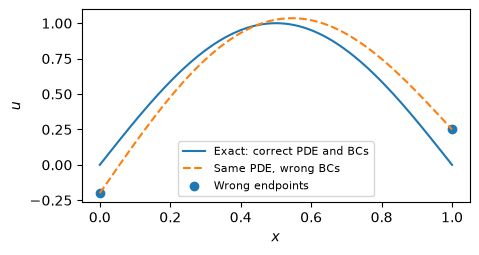

Affine-shift boundary values: -0.20 +0.25


In [7]:
# Even a function with the EXACT PDE residual may have incorrect endpoints.
# Any ax + b disappears after two derivatives, so the PDE cannot detect it.
x_illustration = x_plot.numpy().ravel()
u_target = np.sin(PI * x_illustration)
u_affine = u_target + 0.45 * x_illustration - 0.20
fig, ax = plt.subplots(figsize=(5.0, 2.5))
ax.plot(x_illustration, u_target, label='Exact: correct PDE and BCs')
ax.plot(x_illustration, u_affine, '--', label='Same PDE, wrong BCs')
ax.scatter([0.0, 1.0], [u_affine[0], u_affine[-1]], label='Wrong endpoints')
ax.set(xlabel='$x$', ylabel='$u$')
ax.legend(fontsize=8)
plt.show()
print('Affine-shift boundary values:', f'{u_affine[0]:+.2f}', f'{u_affine[-1]:+.2f}')

In [ ]:
class HardPoisson(nn.Module):
    """Enforce homogeneous Dirichlet BCs by construction."""
    def __init__(self):
        super().__init__()
        self.net = make_mlp()

    def forward(self, x):
        
        # TODO 4: enforce the two homogeneous boundary values exactly.
        
        raise NotImplementedError("Exercise 4: implement the hard Dirichlet ansatz")


def train_hard(model, steps=900, n_f=64):
    """Train only on the PDE residual: no boundary penalty is needed."""
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    history = []
    start = time.perf_counter()
    for _ in range(steps):
        x = torch.rand(n_f, 1, device=device).requires_grad_(True)
        u = model(x)
        loss = (-derivative(derivative(u, x), x) - source(x)).square().mean()
        opt.zero_grad(); loss.backward(); opt.step()
        history.append(loss.detach().item())
    return history, time.perf_counter()-start

hard_model = HardPoisson()
hard_history, hard_time = train_hard(hard_model)
print('Hard:', assess_poisson(hard_model), f'wall time={hard_time:.2f}s')
print('Soft:', (soft_error, soft_residual, soft_bc_error))

# A weak-penalty control uses the same starting weights and collocation sequence
# as the ordinary soft model. Only the BC weight changes.
weak_soft_model = make_mlp()
weak_soft_model.load_state_dict(soft_initial_state)
weak_logs, weak_time = train_poisson(weak_soft_model, bc_weight=1e-3)

# A compact numerical table makes endpoint violations impossible to overlook.
print('\nModel                 rel L2      RMS residual     max |boundary u|')
for name, model in [('Soft (weight 10)', soft_model),
                    ('Soft (weight 1e-3)', weak_soft_model),
                    ('Hard (exact BC)', hard_model)]:
    e_state, e_pde, e_bc = assess_poisson(model)
    print(f'{name:22s} {e_state:9.2e}   {e_pde:11.2e}    {e_bc:13.2e}')

with torch.no_grad():
    u_weak_plot = weak_soft_model(x_plot).numpy().ravel()
    u_hard_plot = hard_model(x_plot).numpy().ravel()
plot_poisson_hard_soft(x_plot.numpy(), u_exact(x_plot).detach().numpy(),
                       u_soft, u_weak_plot, u_hard_plot)


## Bonus exercises 

- A. Change the `Tanh` activation to `ReLU` in the unconstrained field. ReLU networks are piecewise affine, so $u_{xx}=0$ almost everywhere away from kinks: a strong-form residual involving curvature cannot exploit them in the same way. Check the supplied derivative diagnostic. Is this a network expressivity issue, an automatic-differentiation bug, or a mismatch between the activation and PDE formulation?
- B. Change from resampled collocation points to a fixed set. Inspect the residual on points not used for training. Can minimizing an empirical residual over a finite set guarantee a small residual between those points?
- C. With same initialization and training, sweep $\lambda_b\in\{10^{-3},10^{-1},10,10^3\}$. Report boundary conditions mismatch, held-out PDE residual and state error. Why does the numerical value of the (weighted) total loss not provide a meaningful comparison across different penalty weights?
- D. Set $\lambda_b=0$. Identify the nonzero homogeneous solutions of $-u_{xx}=0$. Is the resulting ambiguity a failure of the neural network or a lack of information in the mathematical problem?